#### <font color="skyblue"> Exercise: Constraint optimization problem with integrations in the objective function</font>  #### 

A Least Squared Error (LSE) problem

$$ \min_{a,b>0} \int_0^1 (f(z) - \beta(z|a,b))^2 \;dz$$

where

- $Z = XY$
- $f(z)=\int_z^1 f_Y(y)f_X(z/y) \frac{1}{y} \;dy$
- $X \sim \beta(a_1,b_1)$ and $Y \sim \beta(a_2, b_2)$

Test the following cases: 
- $(a_1, b_1) = (a_2, b_2)=(2, 2)$
- $(a_1, b_1)=(9, 2), \; (a_2, b_2)=(8, 2)$ 

<hr>

<font color=yellow>**Task 1**</font> : Try to figure out the function $f(z)=\int_z^1 f_Y(y)f_X(z/y) \frac{1}{y} \;dy$ 

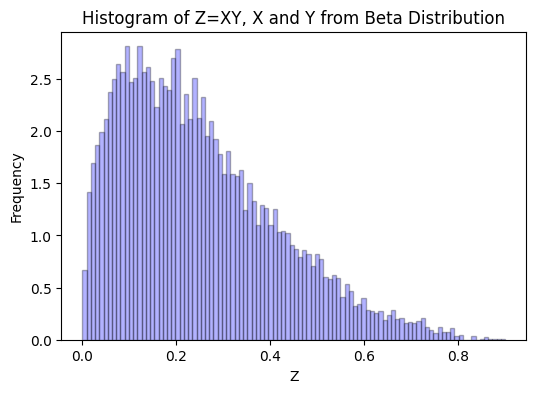

In [21]:
# draw the histogram of data from Z=XY, X, Y from beta distribution
import numpy as np
import matplotlib.pyplot as plt

# Generate data from beta distribution
# np.random.seed(42)
n = 10000
a1, b1 = 2, 2  # parameters for X
a2, b2 = 2, 2  # parameters for Y
X = np.random.beta(a1, b1, n)
Y = np.random.beta(a2, b2, n)
Z = X * Y

# Draw the histogram
fig = plt.figure(figsize=(6, 4))
plt.hist(Z, bins=100, density=True, alpha=0.3, color='blue', edgecolor='black')
plt.xlabel('Z')
plt.ylabel('Frequency')
plt.title('Histogram of Z=XY, X and Y from Beta Distribution')
plt.show()


<font color=yellow>**Task 2**</font> : Draw $f(z)$ and $\beta(z|a,b)$ for some given values of $a$ and $b$.

In [10]:
from scipy.integrate import quad

def f_single(z, f_X, f_Y):
    """
    Compute

        f(z) = ∫_z^1 f_Y(y) f_X(z/y) (1/y) dy

    Parameters
    ----------
    z : float
        Evaluation point.
    f_X : callable
        Density function of X.
    f_Y : callable
        Density function of Y.

    Returns
    -------
    float
    """
    integrand = lambda y: f_Y(y) * f_X(z / y) / y

    value, _ = quad(integrand, z, 1)
    return value

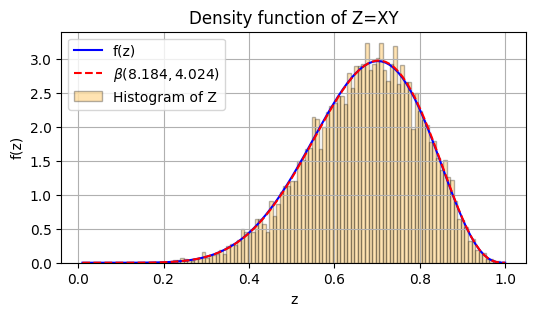

In [53]:
# draw f(z) for z in [0, 1] with 100 points
from scipy.stats import beta
import numpy as np
import matplotlib.pyplot as plt

a1, b1 = 9, 2  # parameters for X
a2, b2 = 9, 2  # parameters for Y
z_values = np.linspace(0.01, 1, 100)
fx = lambda x: beta.pdf(x, a1, b1)
fy = lambda y: beta.pdf(y, a2, b2)

# compute f(z) for z in [0, 1] with 100 points by using f_single
# use vectorization to speed up the computation

# f = np.vectorize(f_single)(z_values, fx, fy)
f = np.zeros_like(z_values)
for i, z in enumerate(z_values):
    f[i] = f_single(z, fx, fy)

# draw the histogram of data from Z=XY, X, Y from beta distribution

n = 10000
X = np.random.beta(a1, b1, n)
Y = np.random.beta(a2, b2, n)
Z = X * Y

# draw a beta pdf with a=2, b=8
a, b = 8.184, 4.024
f_beta = beta.pdf(z_values, a, b)
# draw f and histogram of Z in the same figure
fig = plt.figure(figsize=(6, 3))
plt.plot(z_values, f, color='blue', label='f(z)')
plt.plot(z_values, f_beta, color='red', linestyle='--', label=r'$\beta({},{})$'.format(a, b))
plt.hist(Z, bins=100, density=True, alpha=0.3, color='orange', edgecolor='black', label='Histogram of Z')
plt.xlabel('z')
plt.ylabel('f(z)')
plt.title('Density function of Z=XY')
plt.legend()
plt.grid()
plt.show()

In [57]:
# use method of moments to estimate the parameters of the beta distribution for Z

# calculate the mean and variance of Z
mean_Z = np.mean(Z)
var_Z = np.var(Z)

a_est = mean_Z * (mean_Z * (1 - mean_Z) / var_Z - 1)
b_est = (1 - mean_Z) * (mean_Z * (1 - mean_Z) / var_Z - 1)

# print the estimated parameters up to 3 decimal places
print("Estimated parameters for Z: a = {:.3f}, b = {:.3f}".format(a_est, b_est))

Estimated parameters for Z: a = 8.083, b = 3.990


<font color=yellow>**Task 3**</font> : Draw $F(a,b)=\int_0^1 (f(z) - \beta(z|a,b))^2 \;dz$ as a function of $a$ and $b$ in suitable ranges that show the minimum.

<font color=yellow>**Task 4**</font> : Solve the optimization problem $$\min_{a,b>0} \int_0^1 (f(z) - \beta(z|a,b))^2 \;dz$$ using `scipy.optimize` package and report the optimal values of $a$ and $b$.